# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets.dlr_skyscapes import SkyScapesDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import matplotlib.pyplot as plt

## Visualize images and masks

Total number of patches: 10


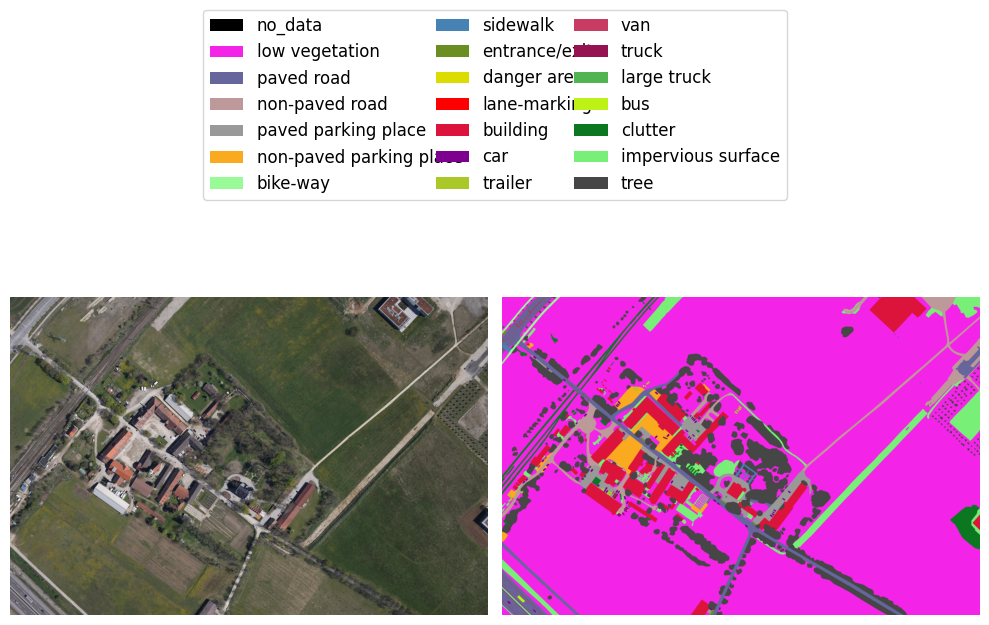

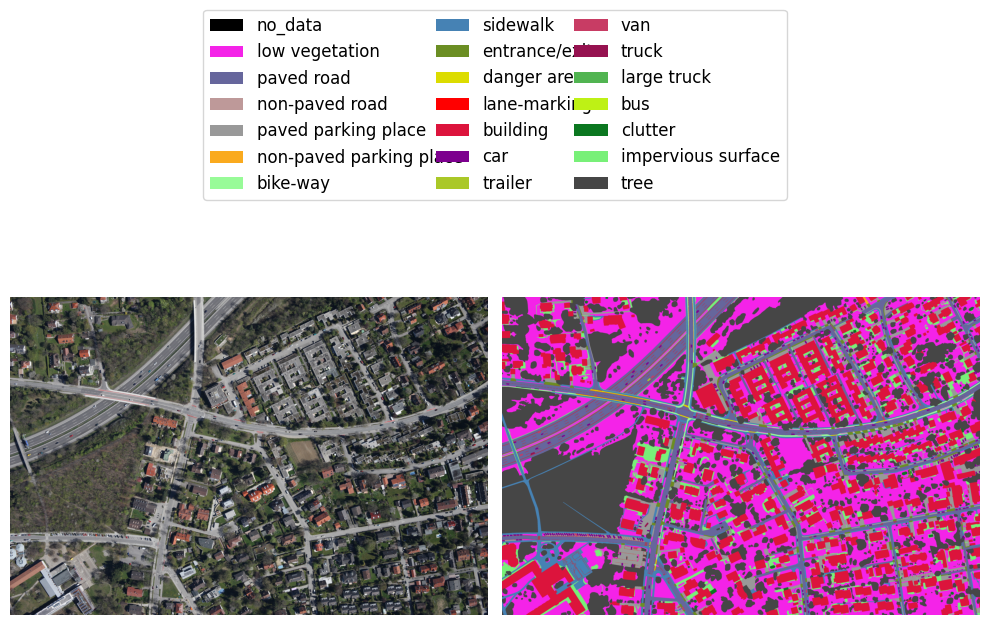

In [ ]:
dataset_config = {
    "data_dir": "./data/SkyScapes/SS_Dense"
}
dataset = SkyScapesDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(4);

In [26]:
dataset.data_distribution_table()

,Number of pixels
no_data,0.0
low vegetation,68874192.0
paved road,17805312.0
non-paved road,1233018.0
paved parking place,7677644.0
non-paved parking place,1625510.0
bike-way,1315386.0
sidewalk,13296690.0
entrance/exit,929868.0
danger area,43897.0


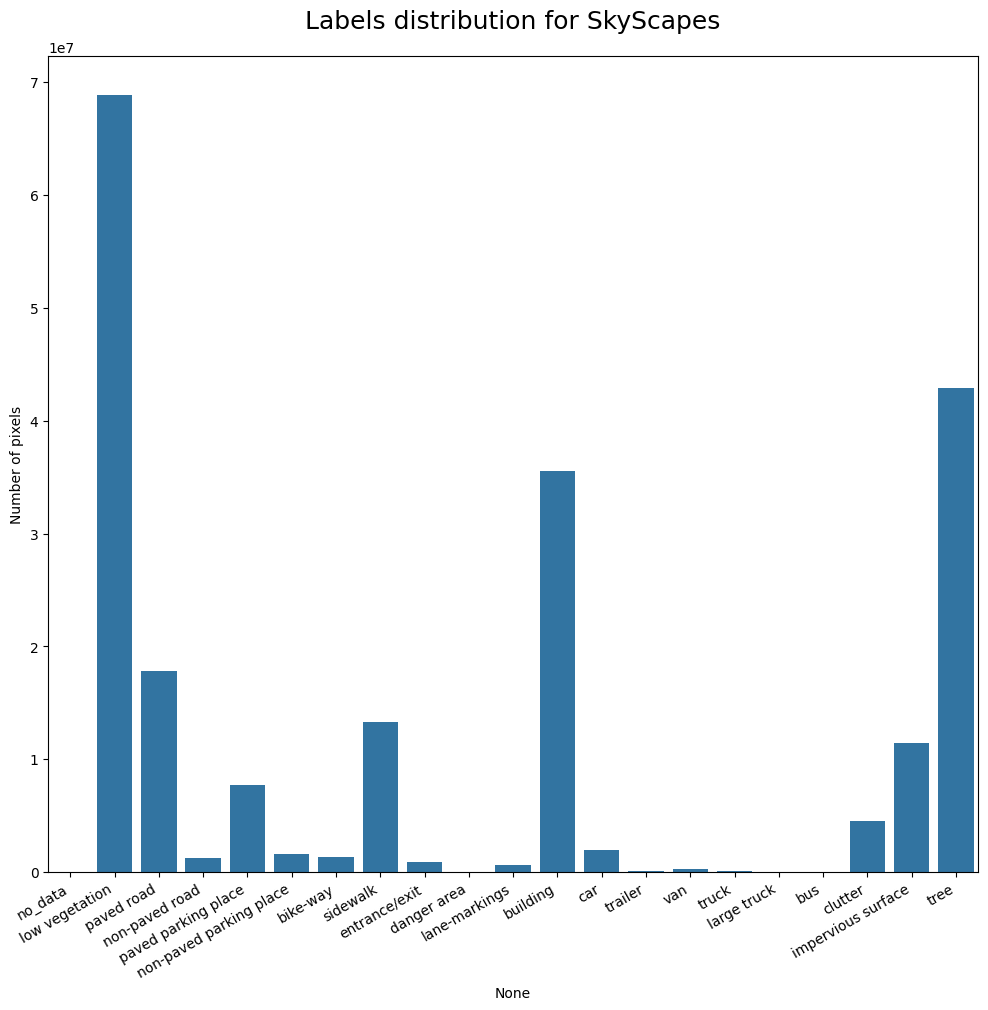

In [27]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/SkyScapes/SS_Dense/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = SkyScapesDataset(train_dataset_config)
len(train_dataset)

8

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/SkyScapes/SS_Dense"
model_config = {
    "num_classes": 21, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [40]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-03 13:10:05,717 INFO Starting training.
training: 100%|██████████| 2/2 [00:18<00:00,  9.41s/it]
2025-03-03 13:10:24,623 INFO epoch: 1, time: 19, loss:  0.90848
testing on train set: 100%|██████████| 2/2 [00:18<00:00,  9.38s/it]
2025-03-03 13:10:45,231 INFO IOU:0.034717538016668825, IOU mean:0.023365840551452403, IOU per Class:[0.00000000e+00 1.94969045e-01 1.00536346e-02 1.51169149e-03
 7.66555046e-03 0.00000000e+00 3.90477808e-06 1.10249870e-02
 1.47212334e-04 0.00000000e+00 0.00000000e+00 8.57135203e-02
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 2.59447802e-02
 1.53648325e-01]
training: 100%|██████████| 2/2 [00:18<00:00,  9.44s/it]
2025-03-03 13:11:04,121 INFO epoch: 2, time: 19, loss:  0.90352
testing on train set: 100%|██████████| 2/2 [00:18<00:00,  9.36s/it]
2025-03-03 13:11:22,859 INFO IOU:0.034209000092868154, IOU mean:0.025597161077748797, IOU per Class:[0.00000000e+00 1.97559694e-01 1.00536346e-02 1.469459

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 2,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/SkyScapes/SS_Dense/val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = SkyScapesDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/SkyScapes/SS_Dense/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2


2025-03-03 13:30:11,196 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SkyScapes/SS_Dense/checkpoint.pth.tar
2025-03-03 13:30:11,658 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SkyScapes/SS_Dense/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 1/1 [00:09<00:00,  9.62s/it]


[{'IOU': 0.02047096556494517,
  'IOU mean': 0.013680526127305534,
  'IOU per Class': array([0.        , 0.05816312, 0.01390839, 0.        , 0.00328048,
         0.        , 0.        , 0.00813293, 0.00020388, 0.        ,
         0.        , 0.14537618, 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.01153781, 0.01152937,
         0.03515888])}]

## Predictions

2025-03-10 09:46:03,547 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SkyScapes/SS_Dense/checkpoint.pth.tar
2025-03-10 09:46:03,901 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SkyScapes/SS_Dense/checkpoint.pth.tar at epoch 11


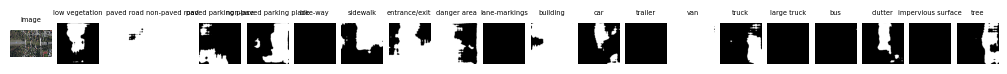

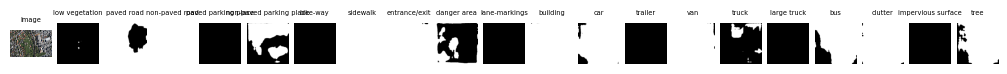

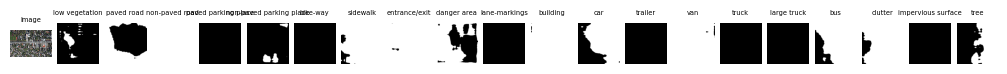

In [ ]:
model_path = "./data/SkyScapes/SS_Dense/checkpoint.pth.tar"
labels = ["low vegetation","paved road","non-paved road","paved parking place","non-paved parking place","bike-way","sidewalk","entrance/exit","danger area","lane-markings","building","car","trailer","van","truck","large truck","bus","clutter","impervious surface","tree"]
transform = ResizeToTensor()
model.load_model(model_path)
plt.rcParams.update({'font.size': 4})

image = image_loader('./data/SkyScapes/SS_Dense/test/images/2012-04-26-Muenchen-Tunnel_4K0G0040.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/SkyScapes/SS_Dense/test/images/2012-04-26-Muenchen-Tunnel_4K0G0060.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/SkyScapes/SS_Dense/test/images/2012-04-26-Muenchen-Tunnel_4K0G0140.jpg')
fig = model.predict_masks(image, labels, transform)